In [1]:
import math
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:

documents = [
    "Apple is sweet",
    "Apple is red",
    "Mango is sweet"
]

document_names = ["D1", "D2", "D3"]

corpus_df = pd.DataFrame({
    "Document": document_names,
    "Text": documents
})

corpus_df


,Document,Text
0,D1,Apple is sweet
1,D2,Apple is red
2,D3,Mango is sweet


In [3]:

def tokenize(text):
    text = text.lower()
    return re.findall(r"\b[a-z]+\b", text)

tokenized_documents = [tokenize(doc) for doc in documents]

for name, tokens in zip(document_names, tokenized_documents):
    print(f"{name}: {tokens}")


D1: ['apple', 'is', 'sweet']
D2: ['apple', 'is', 'red']
D3: ['mango', 'is', 'sweet']


In [4]:

vocabulary = sorted(set(
    word
    for tokens in tokenized_documents
    for word in tokens
))

print("Vocabulary:")
print(vocabulary)
print("\nVocabulary size:", len(vocabulary))


Vocabulary:
['apple', 'is', 'mango', 'red', 'sweet']

Vocabulary size: 5


In [5]:

word_counts = {
    name: len(tokens)
    for name, tokens in zip(document_names, tokenized_documents)
}

word_count_df = pd.DataFrame(
    list(word_counts.items()),
    columns=["Document", "Total Words"]
)

word_count_df


,Document,Total Words
0,D1,3
1,D2,3
2,D3,3


In [6]:

tf_matrix = pd.DataFrame(
    0.0,
    index=document_names,
    columns=vocabulary
)

for doc_name, tokens in zip(document_names, tokenized_documents):
    total_words = len(tokens)

    for term in vocabulary:
        count = tokens.count(term)
        tf_matrix.loc[doc_name, term] = count / total_words

print("Term Frequency (TF) Matrix:")
tf_matrix.round(4)


Term Frequency (TF) Matrix:


,apple,is,mango,red,sweet
D1,0.3333,0.3333,0.0000,0.0000,0.3333
D2,0.3333,0.3333,0.0000,0.3333,0.0000
D3,0.0000,0.3333,0.3333,0.0000,0.3333


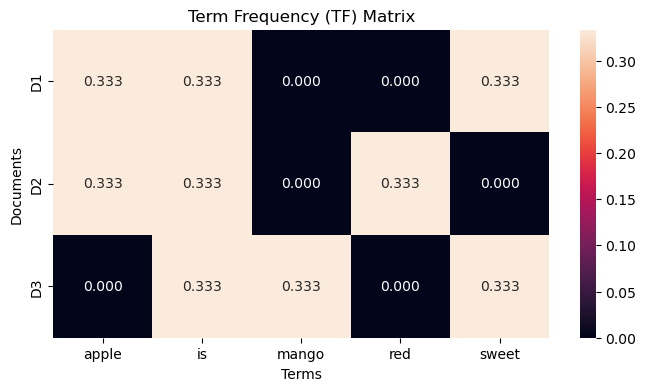

In [7]:

plt.figure(figsize=(8, 4))
sns.heatmap(tf_matrix, annot=True, fmt=".3f")
plt.title("Term Frequency (TF) Matrix")
plt.xlabel("Terms")
plt.ylabel("Documents")
plt.show()


In [8]:

df_values = {}

for term in vocabulary:
    df_values[term] = sum(
        1 for tokens in tokenized_documents
        if term in tokens
    )

df_series = pd.Series(df_values, name="DF")

print("Document Frequency:")
df_series


Document Frequency:


apple    2
is       3
mango    1
red      1
sweet    2
Name: DF, dtype: int64

In [9]:

N = len(documents)

idf_values = {
    term: math.log((N + 1) / (df_values[term] + 1)) + 1
    for term in vocabulary
}

idf_series = pd.Series(idf_values, name="IDF")

df_idf_table = pd.DataFrame({
    "DF": df_series,
    "IDF": idf_series
})

df_idf_table.round(4)


,DF,IDF
apple,2,1.2877
is,3,1.0000
mango,1,1.6931
red,1,1.6931
sweet,2,1.2877


In [10]:

tfidf_raw = tf_matrix.mul(idf_series, axis="columns")

print("Raw TF-IDF Matrix:")
tfidf_raw.round(4)


Raw TF-IDF Matrix:


,apple,is,mango,red,sweet
D1,0.4292,0.3333,0.0000,0.0000,0.4292
D2,0.4292,0.3333,0.0000,0.5644,0.0000
D3,0.0000,0.3333,0.5644,0.0000,0.4292


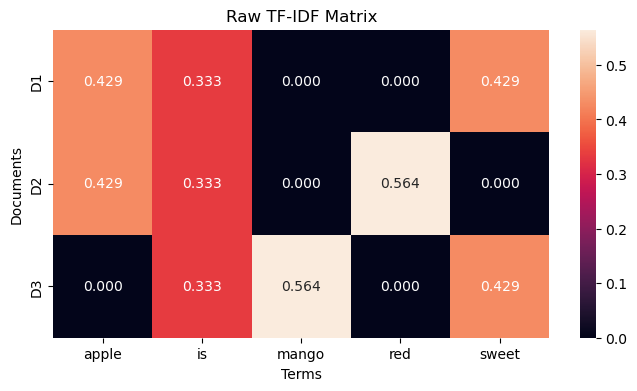

In [11]:

plt.figure(figsize=(8, 4))
sns.heatmap(tfidf_raw, annot=True, fmt=".3f")
plt.title("Raw TF-IDF Matrix")
plt.xlabel("Terms")
plt.ylabel("Documents")
plt.show()
